In [2]:
# ============================================================
# TASK 0: INSTALL REQUIRED LIBRARIES
# ============================================================

!pip install -q kagglehub scikit-image opencv-python seaborn tensorflow

# ============================================================
# IMPORT LIBRARIES
# ============================================================

import os
import random
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import cv2

from pathlib import Path

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    auc,
    roc_auc_score
)

from skimage.feature import hog, local_binary_pattern, graycomatrix, graycoprops

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau
)

print("TensorFlow Version:", tf.__version__)
print("GPU Available:", tf.config.list_physical_devices('GPU'))

TensorFlow Version: 2.20.0
GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [3]:
# ============================================================
# TASK 1: DATA ACQUISITION
# ============================================================

import kagglehub

# Download Chest X-Ray Pneumonia Dataset
path = kagglehub.dataset_download(
    "paultimothymooney/chest-xray-pneumonia"
)

print("Dataset downloaded to:")
print(path)

# ============================================================
# CHECK DATASET STRUCTURE
# ============================================================

for root, dirs, files in os.walk(path):
    level = root.replace(path, '').count(os.sep)

    if level <= 2:
        print("  " * level + os.path.basename(root) + "/")

        if level <= 1:
            for file in files[:5]:
                print("  " * (level + 1) + file)

Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
Dataset downloaded to:
/kaggle/input/chest-xray-pneumonia
chest-xray-pneumonia/
  chest_xray/
    chest_xray/
    __MACOSX/
    val/
    test/
    train/


In [4]:
# ============================================================
# FIND CLASS DIRECTORIES
# ============================================================

dataset_path = Path(path)

normal_dirs = list(dataset_path.rglob("NORMAL"))
pneumonia_dirs = list(dataset_path.rglob("PNEUMONIA"))

print("NORMAL directories:")
for d in normal_dirs:
    print(d)

print("\nPNEUMONIA directories:")
for d in pneumonia_dirs:
    print(d)

 # ============================================================
# COLLECT IMAGE PATHS
# ============================================================

normal_images = []
pneumonia_images = []

for directory in normal_dirs:
    normal_images.extend(
        list(directory.glob("*.jpeg")) +
        list(directory.glob("*.jpg")) +
        list(directory.glob("*.png"))
    )

for directory in pneumonia_dirs:
    pneumonia_images.extend(
        list(directory.glob("*.jpeg")) +
        list(directory.glob("*.jpg")) +
        list(directory.glob("*.png"))
    )

print("Number of NORMAL images:", len(normal_images))
print("Number of PNEUMONIA images:", len(pneumonia_images))

print("Total images:", len(normal_images) + len(pneumonia_images))

NORMAL directories:
/kaggle/input/chest-xray-pneumonia/chest_xray/val/NORMAL
/kaggle/input/chest-xray-pneumonia/chest_xray/test/NORMAL
/kaggle/input/chest-xray-pneumonia/chest_xray/train/NORMAL
/kaggle/input/chest-xray-pneumonia/chest_xray/__MACOSX/chest_xray/val/NORMAL
/kaggle/input/chest-xray-pneumonia/chest_xray/__MACOSX/chest_xray/test/NORMAL
/kaggle/input/chest-xray-pneumonia/chest_xray/__MACOSX/chest_xray/train/NORMAL
/kaggle/input/chest-xray-pneumonia/chest_xray/chest_xray/val/NORMAL
/kaggle/input/chest-xray-pneumonia/chest_xray/chest_xray/test/NORMAL
/kaggle/input/chest-xray-pneumonia/chest_xray/chest_xray/train/NORMAL

PNEUMONIA directories:
/kaggle/input/chest-xray-pneumonia/chest_xray/val/PNEUMONIA
/kaggle/input/chest-xray-pneumonia/chest_xray/test/PNEUMONIA
/kaggle/input/chest-xray-pneumonia/chest_xray/train/PNEUMONIA
/kaggle/input/chest-xray-pneumonia/chest_xray/__MACOSX/chest_xray/val/PNEUMONIA
/kaggle/input/chest-xray-pneumonia/chest_xray/__MACOSX/chest_xray/test/PNEUMON

In [5]:
# ============================================================
# CREATE DATAFRAME
# ============================================================

data = []

for img_path in normal_images:
    data.append({
        "filepath": str(img_path),
        "label": 0,
        "class": "NORMAL"
    })

for img_path in pneumonia_images:
    data.append({
        "filepath": str(img_path),
        "label": 1,
        "class": "PNEUMONIA"
    })

df = pd.DataFrame(data)

# Shuffle dataset
df = df.sample(frac=1, random_state=42).reset_index(drop=True)

print(df.head())
print("\nDataset shape:", df.shape)

                                            filepath  label      class
0  /kaggle/input/chest-xray-pneumonia/chest_xray/...      0     NORMAL
1  /kaggle/input/chest-xray-pneumonia/chest_xray/...      1  PNEUMONIA
2  /kaggle/input/chest-xray-pneumonia/chest_xray/...      1  PNEUMONIA
3  /kaggle/input/chest-xray-pneumonia/chest_xray/...      1  PNEUMONIA
4  /kaggle/input/chest-xray-pneumonia/chest_xray/...      0     NORMAL

Dataset shape: (17568, 3)


Images per class:
class
PNEUMONIA    12819
NORMAL        4749
Name: count, dtype: int64


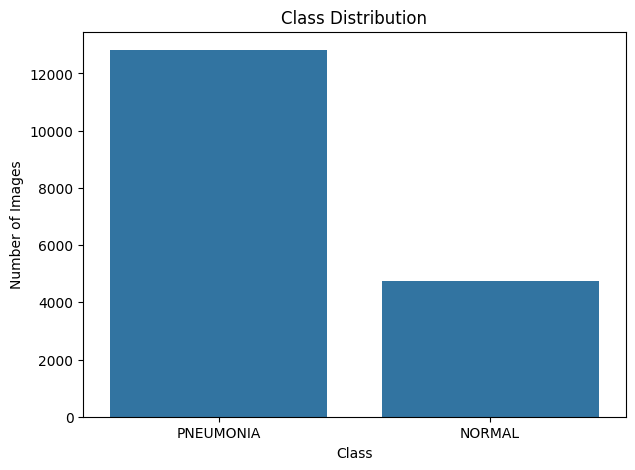

In [6]:
# ============================================================
# CLASS BALANCE
# ============================================================

class_counts = df["class"].value_counts()

print("Images per class:")
print(class_counts)

plt.figure(figsize=(7,5))

sns.barplot(
    x=class_counts.index,
    y=class_counts.values
)

plt.title("Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.show()

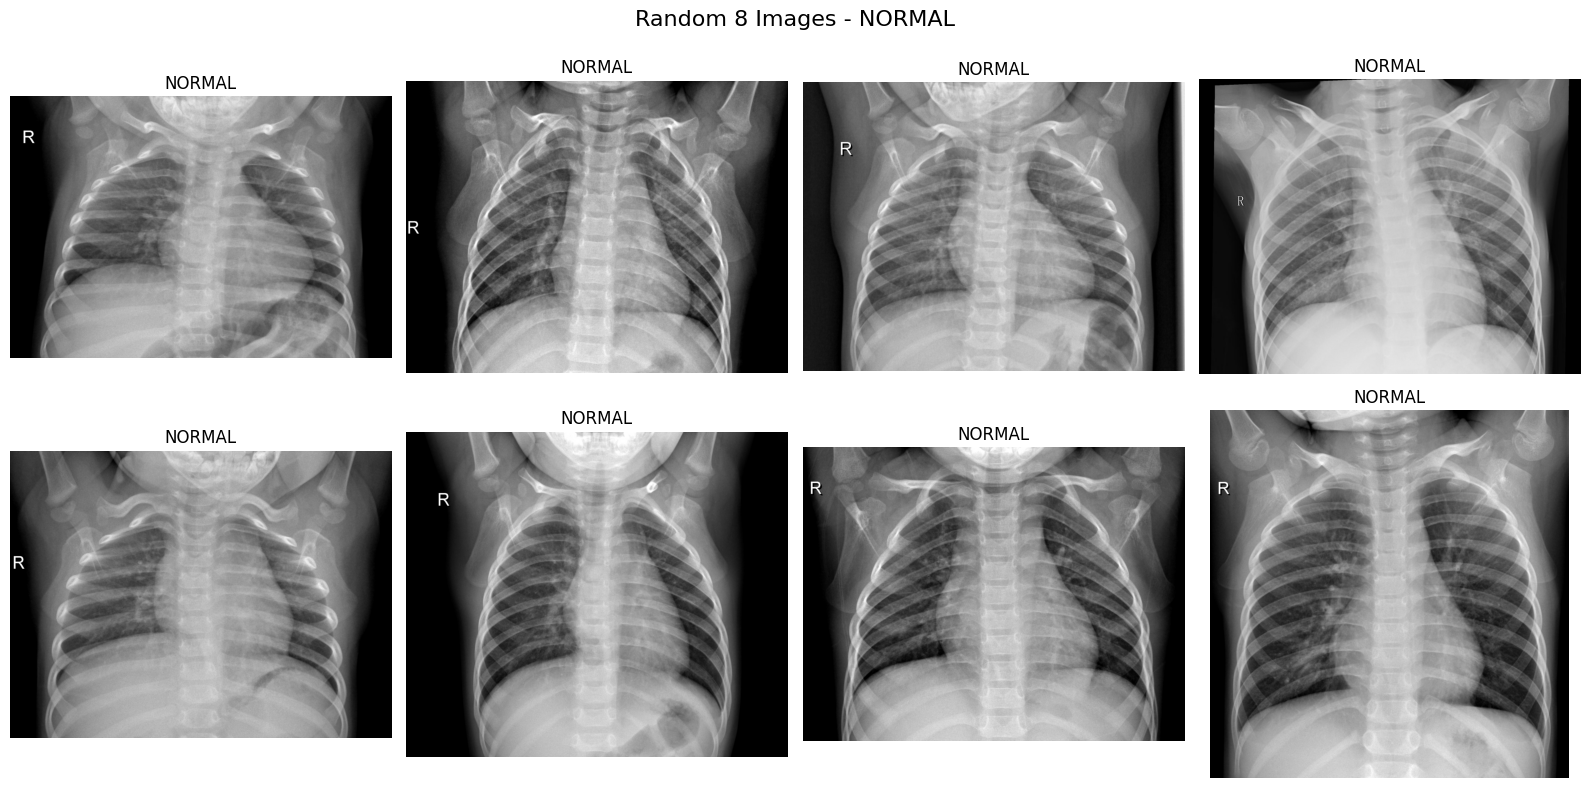

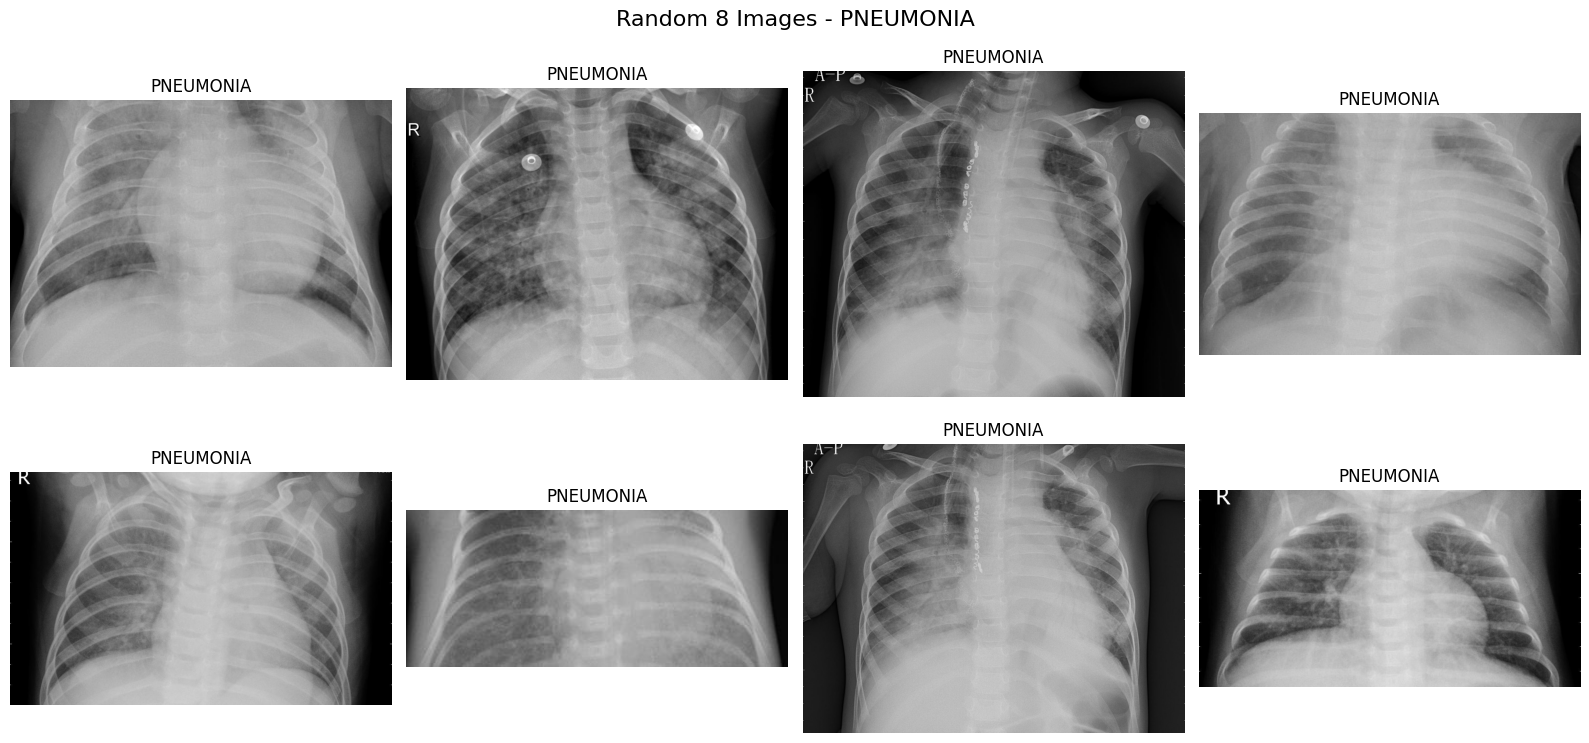

In [9]:
# ============================================================
# DISPLAY RANDOM IMAGES
# ============================================================

def display_random_images(class_name, n=8):
    # Filter out __MACOSX files from the dataframe to avoid loading empty files
    valid_df = df[~df["filepath"].str.contains("__MACOSX")]

    images = valid_df[valid_df["class"] == class_name].sample(
        n=n,
        random_state=42
    )

    plt.figure(figsize=(16, 8))

    loaded_count = 0
    for i, (_, row) in enumerate(images.iterrows()):
        image = cv2.imread(row["filepath"])
        if image is None:
            continue

        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        plt.subplot(2, 4, loaded_count + 1)
        plt.imshow(image, cmap="gray")
        plt.title(class_name)
        plt.axis("off")
        loaded_count += 1
        if loaded_count >= n:
            break

    plt.suptitle(
        f"Random {loaded_count} Images - {class_name}",
        fontsize=16
    )

    plt.tight_layout()
    plt.show()


display_random_images("NORMAL", 8)
display_random_images("PNEUMONIA", 8)

Image size: 128 x 128


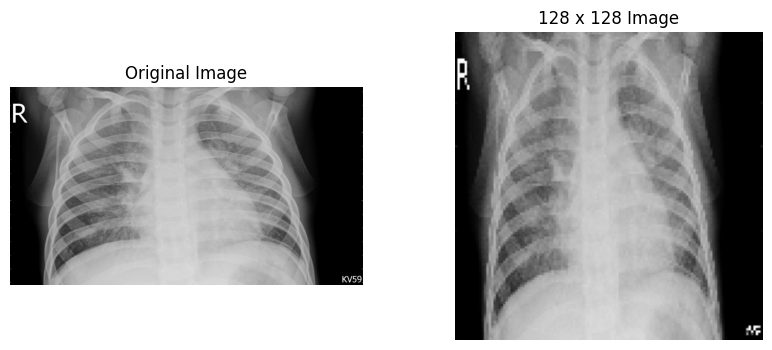

In [11]:
# ============================================================
# TASK 2: IMAGE PREPROCESSING
# ============================================================

IMG_SIZE = 128

print("Image size:", IMG_SIZE, "x", IMG_SIZE)

# ============================================================
# LOAD AND PREPROCESS IMAGE
# ============================================================

def load_image(filepath, size=128):

    image = cv2.imread(filepath)

    if image is None:
        return None

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # Resize
    image = cv2.resize(image, (size, size))

    # Normalize
    image = image.astype(np.float32) / 255.0

    return image

# ============================================================
# VISUALIZE PREPROCESSED IMAGE
# ============================================================

# Filter out metadata files to obtain a valid image
valid_df = df[~df["filepath"].str.contains("__MACOSX")]
sample_path = valid_df.iloc[0]["filepath"]

original = cv2.imread(sample_path)
original = cv2.cvtColor(original, cv2.COLOR_BGR2RGB)

processed = cv2.resize(
    original,
    (IMG_SIZE, IMG_SIZE)
)

plt.figure(figsize=(10,4))

plt.subplot(1,2,1)
plt.imshow(original)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(processed)
plt.title("128 x 128 Image")
plt.axis("off")

plt.show()

HOG feature vector shape: (8100,)
Number of HOG features: 8100


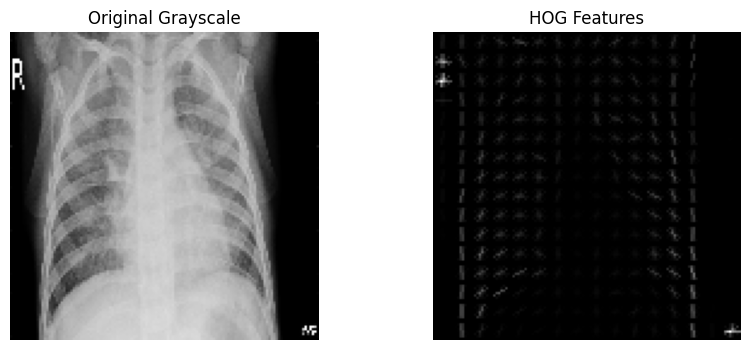

In [12]:
# ============================================================
# GRAYSCALE CONVERSION
# ============================================================

def load_grayscale(filepath, size=128):

    image = cv2.imread(filepath)

    if image is None:
        return None

    gray = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2GRAY
    )

    gray = cv2.resize(
        gray,
        (size, size)
    )

    return gray

# ============================================================
# HOG FEATURE EXTRACTION
# ============================================================

def extract_hog(image):

    features = hog(
        image,
        orientations=9,
        pixels_per_cell=(8, 8),
        cells_per_block=(2, 2),
        block_norm="L2-Hys"
    )

    return features


# Test HOG
gray_image = load_grayscale(sample_path)

hog_features = extract_hog(gray_image)

print("HOG feature vector shape:", hog_features.shape)
print("Number of HOG features:", len(hog_features))

# ============================================================
# HOG VISUALIZATION
# ============================================================

features, hog_image = hog(
    gray_image,
    orientations=9,
    pixels_per_cell=(8,8),
    cells_per_block=(2,2),
    block_norm="L2-Hys",
    visualize=True
)

plt.figure(figsize=(10,4))

plt.subplot(1,2,1)
plt.imshow(gray_image, cmap="gray")
plt.title("Original Grayscale")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(hog_image, cmap="gray")
plt.title("HOG Features")
plt.axis("off")

plt.show()

LBP feature vector shape: (10,)
Number of LBP features: 10
LBP feature vector shape: (10,)
Number of LBP features: 10


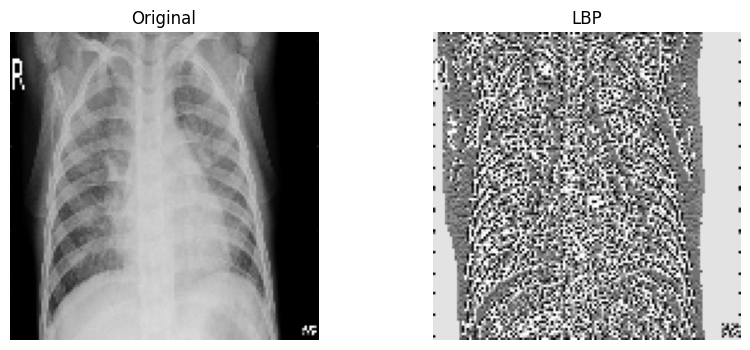

In [14]:
# ============================================================
# LOCAL BINARY PATTERN (LBP)
# ============================================================

def extract_lbp(image):

    radius = 1
    points = 8 * radius

    lbp = local_binary_pattern(
        image,
        points,
        radius,
        method="uniform"
    )

    # Histogram of LBP
    n_bins = points + 2

    histogram, _ = np.histogram(
        lbp.ravel(),
        bins=n_bins,
        range=(0, n_bins)
    )

    # Normalize
    histogram = histogram.astype("float")
    histogram /= (histogram.sum() + 1e-7)

    return histogram


lbp_features = extract_lbp(gray_image)

print("LBP feature vector shape:", lbp_features.shape)
print("Number of LBP features:", len(lbp_features))

# ============================================================
# LOCAL BINARY PATTERN (LBP)
# ============================================================

def extract_lbp(image):

    radius = 1
    points = 8 * radius

    lbp = local_binary_pattern(
        image,
        points,
        radius,
        method="uniform"
    )

    # Histogram of LBP
    n_bins = points + 2

    histogram, _ = np.histogram(
        lbp.ravel(),
        bins=n_bins,
        range=(0, n_bins)
    )

    # Normalize
    histogram = histogram.astype("float")
    histogram /= (histogram.sum() + 1e-7)

    return histogram


lbp_features = extract_lbp(gray_image)

print("LBP feature vector shape:", lbp_features.shape)
print("Number of LBP features:", len(lbp_features))

# ============================================================
# LBP VISUALIZATION
# ============================================================

radius = 1
points = 8 * radius

lbp_image = local_binary_pattern(
    gray_image,
    points,
    radius,
    method="uniform"
)

plt.figure(figsize=(10,4))

plt.subplot(1,2,1)
plt.imshow(gray_image, cmap="gray")
plt.title("Original")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(lbp_image, cmap="gray")
plt.title("LBP")
plt.axis("off")

plt.show()



In [15]:
# ============================================================
# GLCM FEATURE EXTRACTION
# ============================================================

def extract_glcm(image):

    # Reduce gray levels
    image = (image / 32).astype(np.uint8)

    glcm = graycomatrix(
        image,
        distances=[1],
        angles=[0],
        levels=8,
        symmetric=True,
        normed=True
    )

    features = []

    properties = [
        "contrast",
        "dissimilarity",
        "homogeneity",
        "energy",
        "correlation",
        "ASM"
    ]

    for prop in properties:

        value = graycoprops(
            glcm,
            prop
        )[0, 0]

        features.append(value)

    return np.array(features)


glcm_features = extract_glcm(gray_image)

print("GLCM features:")
print(glcm_features)

print("\nGLCM feature vector shape:",
      glcm_features.shape)



GLCM features:
[0.46887303 0.27054626 0.8789375  0.3536173  0.9496175  0.12504519]

GLCM feature vector shape: (6,)


In [16]:
# ============================================================
# COMBINE FEATURE VECTORS
# ============================================================

combined_features = np.concatenate([
    hog_features,
    lbp_features,
    glcm_features
])

print("HOG features:", len(hog_features))
print("LBP features:", len(lbp_features))
print("GLCM features:", len(glcm_features))

print("\nCombined feature vector size:",
      len(combined_features))

HOG features: 8100
LBP features: 10
GLCM features: 6

Combined feature vector size: 8116


In [17]:
# ============================================================
# EXTRACT FEATURES FROM DATASET
# ============================================================

MAX_FEATURE_IMAGES = len(df)

feature_vectors = []
feature_labels = []

for index, row in df.iloc[:MAX_FEATURE_IMAGES].iterrows():

    gray = load_grayscale(
        row["filepath"],
        IMG_SIZE
    )

    if gray is None:
        continue

    # HOG
    hog_feat = extract_hog(gray)

    # LBP
    lbp_feat = extract_lbp(gray)

    # GLCM
    glcm_feat = extract_glcm(gray)

    # Combine
    combined = np.concatenate([
        hog_feat,
        lbp_feat,
        glcm_feat
    ])

    feature_vectors.append(combined)
    feature_labels.append(row["label"])

    if (index + 1) % 500 == 0:
        print(
            "Processed:",
            index + 1,
            "images"
        )

X_features = np.array(feature_vectors)
y_features = np.array(feature_labels)

print("\nFeature matrix shape:")
print(X_features.shape)

print("\nLabel shape:")
print(y_features.shape)

# ============================================================
# SAVE FEATURES
# ============================================================

np.save(
    "/content/chest_xray_features.npy",
    X_features
)

np.save(
    "/content/chest_xray_labels.npy",
    y_features
)

print("Features saved successfully.")

Processed: 500 images
Processed: 1500 images
Processed: 2000 images
Processed: 2500 images
Processed: 3000 images
Processed: 3500 images
Processed: 4500 images
Processed: 5000 images
Processed: 6000 images
Processed: 6500 images
Processed: 7500 images
Processed: 8500 images
Processed: 9000 images
Processed: 9500 images
Processed: 10500 images
Processed: 11500 images
Processed: 12000 images
Processed: 12500 images
Processed: 13500 images
Processed: 14000 images
Processed: 15000 images
Processed: 16500 images
Processed: 17500 images

Feature matrix shape:
(11712, 8116)

Label shape:
(11712,)
Features saved successfully.


In [18]:
# ============================================================
# 70% TRAIN
# 15% VALIDATION
# 15% TEST
# ============================================================

X_train, X_temp, y_train, y_temp = train_test_split(
    X_features,
    y_features,
    test_size=0.30,
    random_state=42,
    stratify=y_features
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training data:", X_train.shape)
print("Validation data:", X_val.shape)
print("Testing data:", X_test.shape)

print("\nTraining percentage:",
      len(X_train) / len(X_features) * 100)

print("Validation percentage:",
      len(X_val) / len(X_features) * 100)

print("Testing percentage:",
      len(X_test) / len(X_features) * 100)

Training data: (8198, 8116)
Validation data: (1757, 8116)
Testing data: (1757, 8116)

Training percentage: 69.99658469945356
Validation percentage: 15.001707650273225
Testing percentage: 15.001707650273225


In [19]:
# ============================================================
# PREPARE IMAGE DATA FOR CNN
# ============================================================

def prepare_cnn_images(dataframe, size=128):

    images = []
    labels = []

    for _, row in dataframe.iterrows():

        image = cv2.imread(row["filepath"])

        if image is None:
            continue

        image = cv2.cvtColor(
            image,
            cv2.COLOR_BGR2RGB
        )

        image = cv2.resize(
            image,
            (size, size)
        )

        image = image.astype(
            np.float32
        ) / 255.0

        images.append(image)
        labels.append(row["label"])

    return (
        np.array(images),
        np.array(labels)
    )

 # ============================================================
# IMAGE DATA SPLIT
# ============================================================

train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    random_state=42,
    stratify=df["label"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["label"]
)

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))

# ============================================================
# LOAD CNN DATA
# ============================================================

X_train_img, y_train_img = prepare_cnn_images(
    train_df,
    IMG_SIZE
)

X_val_img, y_val_img = prepare_cnn_images(
    val_df,
    IMG_SIZE
)

X_test_img, y_test_img = prepare_cnn_images(
    test_df,
    IMG_SIZE
)

print("X_train:", X_train_img.shape)
print("X_val:", X_val_img.shape)
print("X_test:", X_test_img.shape)

Training images: 12297
Validation images: 2635
Testing images: 2636
X_train: (8157, 128, 128, 3)
X_val: (1788, 128, 128, 3)
X_test: (1767, 128, 128, 3)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 126, 126, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 61, 61, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 28, 28, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,305,665 (12.61 MB)

 Trainable params: 3,305,217 (12.61 MB)

 Non-trainable params: 448 (1.75 KB)

Epoch 1/20
255/255 ━━━━━━━━━━━━━━━━━━━━ 21s 48ms/step - accuracy: 0.8949 - loss: 0.3634 - val_accuracy: 0.7276 - val_loss: 11.4330 - learning_rate: 0.0010
Epoch 2/20
255/255 ━━━━━━━━━━━━━━━━━━━━ 6s 24ms/step - accuracy: 0.9323 - loss: 0.1900 - val_accuracy: 0.7746 - val_loss: 0.7998 - learning_rate: 0.0010
Epoch 3/20
255/255 ━━━━━━━━━━━━━━━━━━━━ 10s 24ms/step - accuracy: 0.9459 - loss: 0.1524 - val_accuracy: 0.9457 - val_loss: 0.1341 - learning_rate: 0.0010
Epoch 4/20
255/255 ━━━━━━━━━━━━━━━━━━━━ 6s 24ms/step - accuracy: 0.9474 - loss: 0.1362 - val_accuracy: 0.9519 - val_loss: 0.1361 - learning_rate: 0.0010
Epoch 5/20
255/255 ━━━━━━━━━━━━━━━━━━━━ 6s 23ms/step - accuracy: 0.9580 - loss: 0.1158 - val_accuracy: 0.8859 - val_loss: 0.5710 - learning_rate: 0.0010
Epoch 6/20
255/255 ━━━━━━━━━━━━━━━━━━━━ 6s 24ms/step - accuracy: 0.9658 - loss: 0.0937 - val_accuracy: 0.9413 - val_loss: 0.2161 - learning_rate: 5.0000e-04
Epoch 7/20
255/255 ━━━━━━━━━━━━━━━━━━━━ 6s 24ms/step - accuracy: 0.9732 - l

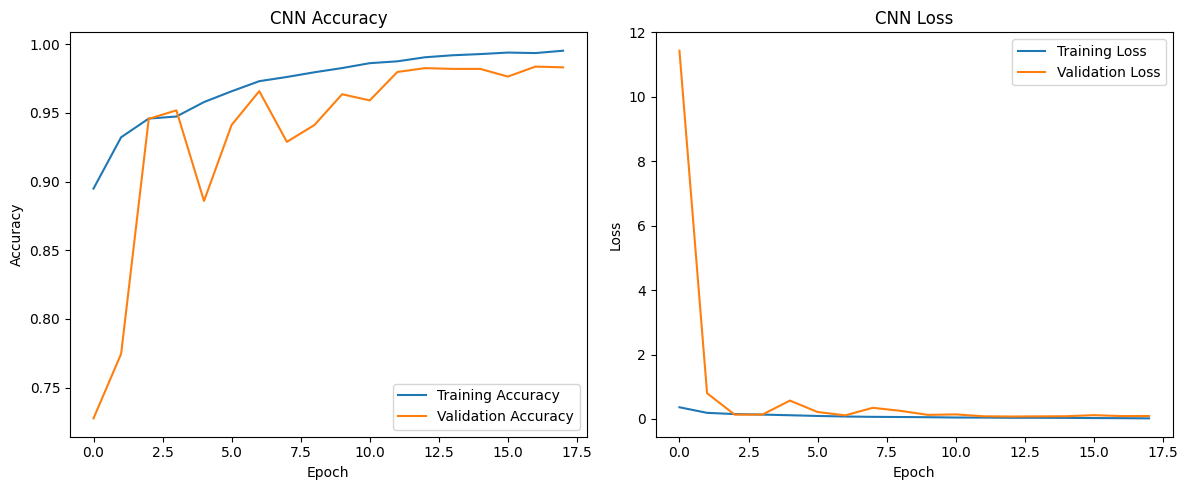

In [20]:
# ============================================================
# CNN MODEL
# ============================================================

def create_cnn(
    filters1=32,
    filters2=64,
    dense_units=128,
    dropout=0.5,
    learning_rate=0.001
):

    model = models.Sequential([

        # Input
        layers.Input(
            shape=(128, 128, 3)
        ),

        # CNN Block 1
        layers.Conv2D(
            filters1,
            (3,3),
            activation="relu"
        ),

        layers.BatchNormalization(),

        layers.MaxPooling2D(
            (2,2)
        ),

        # CNN Block 2
        layers.Conv2D(
            filters2,
            (3,3),
            activation="relu"
        ),

        layers.BatchNormalization(),

        layers.MaxPooling2D(
            (2,2)
        ),

        # CNN Block 3
        layers.Conv2D(
            filters2 * 2,
            (3,3),
            activation="relu"
        ),

        layers.BatchNormalization(),

        layers.MaxPooling2D(
            (2,2)
        ),

        # Flatten
        layers.Flatten(),

        # Fully Connected
        layers.Dense(
            dense_units,
            activation="relu"
        ),

        layers.Dropout(
            dropout
        ),

        # Binary output
        layers.Dense(
            1,
            activation="sigmoid"
        )
    ])

    optimizer = keras.optimizers.Adam(
        learning_rate=learning_rate
    )

    model.compile(
        optimizer=optimizer,
        loss="binary_crossentropy",
        metrics=[
            "accuracy"
        ]
    )

    return model


cnn_model = create_cnn()

cnn_model.summary()

# ============================================================
# TRAIN CNN
# ============================================================

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-6
)

history = cnn_model.fit(
    X_train_img,
    y_train_img,

    validation_data=(
        X_val_img,
        y_val_img
    ),

    epochs=20,
    batch_size=32,

    callbacks=[
        early_stopping,
        reduce_lr
    ],

    verbose=1
)

# ============================================================
# TRAINING HISTORY
# ============================================================

plt.figure(figsize=(12,5))

# Accuracy
plt.subplot(1,2,1)

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("CNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()


# Loss
plt.subplot(1,2,2)

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title("CNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [21]:
# ============================================================
# HYPERPARAMETER TUNING WITH 3-FOLD CROSS-VALIDATION
# ============================================================

from sklearn.model_selection import StratifiedKFold

# Use a subset for CV to reduce Colab runtime
CV_SAMPLES = min(
    1500,
    len(X_train_img)
)

X_cv = X_train_img[:CV_SAMPLES]
y_cv = y_train_img[:CV_SAMPLES]

skf = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

parameter_sets = [

    {
        "filters1": 16,
        "filters2": 32,
        "dense_units": 64,
        "dropout": 0.5,
        "learning_rate": 0.001
    },

    {
        "filters1": 32,
        "filters2": 64,
        "dense_units": 128,
        "dropout": 0.5,
        "learning_rate": 0.001
    },

    {
        "filters1": 32,
        "filters2": 64,
        "dense_units": 128,
        "dropout": 0.3,
        "learning_rate": 0.0005
    }
]

cv_results = []

for param_id, params in enumerate(parameter_sets):

    print("\n====================================")
    print("Parameter Set:", param_id + 1)
    print(params)
    print("====================================")

    fold_scores = []

    for fold, (train_idx, val_idx) in enumerate(
        skf.split(X_cv, y_cv)
    ):

        print("\nFold:", fold + 1)

        model = create_cnn(
            **params
        )

        model.fit(
            X_cv[train_idx],
            y_cv[train_idx],
            validation_data=(
                X_cv[val_idx],
                y_cv[val_idx]
            ),
            epochs=5,
            batch_size=32,
            verbose=0
        )

        probabilities = model.predict(
            X_cv[val_idx],
            verbose=0
        ).ravel()

        predictions = (
            probabilities >= 0.5
        ).astype(int)

        score = accuracy_score(
            y_cv[val_idx],
            predictions
        )

        fold_scores.append(score)

        print(
            "Fold Accuracy:",
            round(score, 4)
        )

    mean_score = np.mean(
        fold_scores
    )

    cv_results.append({
        "Parameter_Set": param_id + 1,
        "Mean_CV_Accuracy": mean_score
    })

    print(
        "Mean CV Accuracy:",
        round(mean_score, 4)
    )


cv_results_df = pd.DataFrame(
    cv_results
)

print("\nCross-validation results:")
display(cv_results_df)


Parameter Set: 1
{'filters1': 16, 'filters2': 32, 'dense_units': 64, 'dropout': 0.5, 'learning_rate': 0.001}

Fold: 1
Fold Accuracy: 0.732

Fold: 2
Fold Accuracy: 0.732

Fold: 3
Fold Accuracy: 0.73
Mean CV Accuracy: 0.7313

Parameter Set: 2
{'filters1': 32, 'filters2': 64, 'dense_units': 128, 'dropout': 0.5, 'learning_rate': 0.001}

Fold: 1
Fold Accuracy: 0.732

Fold: 2
Fold Accuracy: 0.732

Fold: 3
Fold Accuracy: 0.73
Mean CV Accuracy: 0.7313

Parameter Set: 3
{'filters1': 32, 'filters2': 64, 'dense_units': 128, 'dropout': 0.3, 'learning_rate': 0.0005}

Fold: 1
Fold Accuracy: 0.732

Fold: 2
Fold Accuracy: 0.732

Fold: 3
Fold Accuracy: 0.73
Mean CV Accuracy: 0.7313

Cross-validation results:


,Parameter_Set,Mean_CV_Accuracy
0,1,0.731333
1,2,0.731333
2,3,0.731333


In [22]:
# ============================================================
# BEST HYPERPARAMETERS
# ============================================================

best_index = cv_results_df[
    "Mean_CV_Accuracy"
].idxmax()

best_parameter_number = cv_results_df.loc[
    best_index,
    "Parameter_Set"
]

best_params = parameter_sets[
    int(best_parameter_number) - 1
]

print("Best Parameter Set:")
print(best_params)

Best Parameter Set:
{'filters1': 16, 'filters2': 32, 'dense_units': 64, 'dropout': 0.5, 'learning_rate': 0.001}


In [23]:
# ============================================================
# FINAL CNN USING BEST PARAMETERS
# ============================================================

final_model = create_cnn(
    **best_params
)

final_history = final_model.fit(
    X_train_img,
    y_train_img,

    validation_data=(
        X_val_img,
        y_val_img
    ),

    epochs=20,
    batch_size=32,

    callbacks=[
        EarlyStopping(
            monitor="val_loss",
            patience=5,
            restore_best_weights=True
        ),

        ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=2
        )
    ],

    verbose=1
)

Epoch 1/20
255/255 ━━━━━━━━━━━━━━━━━━━━ 15s 39ms/step - accuracy: 0.9006 - loss: 0.2889 - val_accuracy: 0.7276 - val_loss: 12.9428 - learning_rate: 0.0010
Epoch 2/20
255/255 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - accuracy: 0.9409 - loss: 0.1610 - val_accuracy: 0.8003 - val_loss: 0.6066 - learning_rate: 0.0010
Epoch 3/20
255/255 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - accuracy: 0.9470 - loss: 0.1595 - val_accuracy: 0.9239 - val_loss: 0.1962 - learning_rate: 0.0010
Epoch 4/20
255/255 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - accuracy: 0.9544 - loss: 0.1253 - val_accuracy: 0.9239 - val_loss: 0.2219 - learning_rate: 0.0010
Epoch 5/20
255/255 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - accuracy: 0.9610 - loss: 0.1085 - val_accuracy: 0.9474 - val_loss: 0.1400 - learning_rate: 0.0010
Epoch 6/20
255/255 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - accuracy: 0.9627 - loss: 0.1040 - val_accuracy: 0.9541 - val_loss: 0.1232 - learning_rate: 0.0010
Epoch 7/20
255/255 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - accuracy: 0.9679 - loss: 

In [24]:
# ============================================================
# MODEL PREDICTIONS
# ============================================================

y_probability = final_model.predict(
    X_test_img
).ravel()

y_prediction = (
    y_probability >= 0.5
).astype(int)

print("Predictions generated successfully.")

56/56 ━━━━━━━━━━━━━━━━━━━━ 3s 32ms/step
Predictions generated successfully.


In [25]:
# ============================================================
# EVALUATION METRICS
# ============================================================

accuracy = accuracy_score(
    y_test_img,
    y_prediction
)

precision = precision_score(
    y_test_img,
    y_prediction
)

recall = recall_score(
    y_test_img,
    y_prediction
)

f1 = f1_score(
    y_test_img,
    y_prediction
)

auroc = roc_auc_score(
    y_test_img,
    y_probability
)

print("======================================")
print("CNN MODEL PERFORMANCE")
print("======================================")

print(
    "Accuracy :", round(accuracy, 4)
)

print(
    "Precision:", round(precision, 4)
)

print(
    "Recall   :", round(recall, 4)
)

print(
    "F1 Score :", round(f1, 4)
)

print(
    "AUROC    :", round(auroc, 4)
)

CNN MODEL PERFORMANCE
Accuracy : 0.9723
Precision: 0.9928
Recall   : 0.969
F1 Score : 0.9808
AUROC    : 0.9938


In [26]:
# ============================================================
# CLASSIFICATION REPORT
# ============================================================

print(
    classification_report(
        y_test_img,
        y_prediction,
        target_names=[
            "NORMAL",
            "PNEUMONIA"
        ]
    )
)

              precision    recall  f1-score   support

      NORMAL       0.92      0.98      0.95       478
   PNEUMONIA       0.99      0.97      0.98      1289

    accuracy                           0.97      1767
   macro avg       0.96      0.98      0.97      1767
weighted avg       0.97      0.97      0.97      1767



/tmp/ipykernel_1672/3642919727.py:142: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


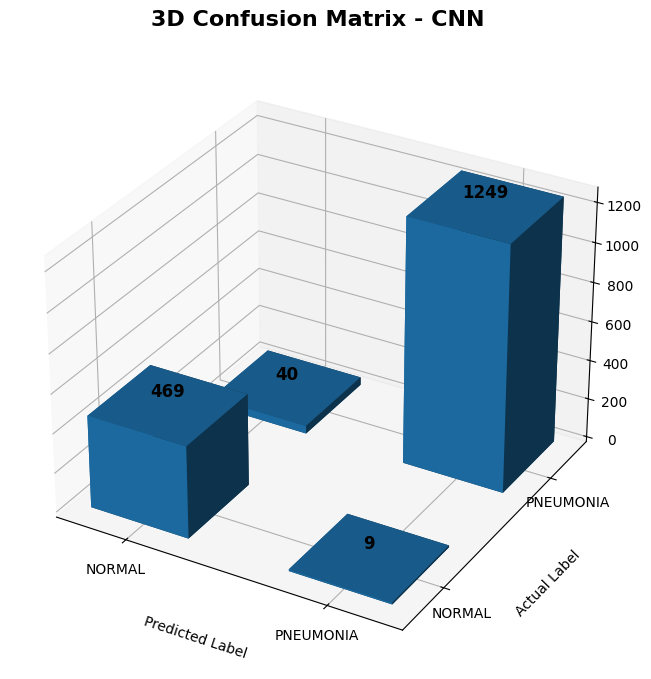


3D CONFUSION MATRIX VALUES
--------------------------------
True Negative (TN): 469
False Positive (FP): 9
False Negative (FN): 40
True Positive (TP): 1249


In [33]:
# ================================================================
# 3D CONFUSION MATRIX
# ================================================================

from mpl_toolkits.mplot3d import Axes3D

# Calculate confusion matrix
cm = confusion_matrix(
    y_test_img,
    y_prediction
)

# Extract values
TN, FP, FN, TP = cm.ravel()

# Matrix values
values = np.array([
    [TN, FP],
    [FN, TP]
])

# Coordinates
x_positions = np.array([0, 1])
y_positions = np.array([0, 1])

x, y = np.meshgrid(
    x_positions,
    y_positions
)

x = x.flatten()
y = y.flatten()

z = np.zeros_like(x)

dz = values.flatten()

# Bar dimensions
dx = np.ones_like(z) * 0.5
dy = np.ones_like(z) * 0.5


# ================================================================
# CREATE 3D PLOT
# ================================================================

fig = plt.figure(
    figsize=(10, 8)
)

ax = fig.add_subplot(
    111,
    projection="3d"
)


# Create 3D bars
ax.bar3d(
    x,
    y,
    z,
    dx,
    dy,
    dz,
    shade=True
)


# ================================================================
# ADD VALUES ON TOP OF BARS
# ================================================================

for xpos, ypos, height in zip(
    x,
    y,
    dz
):

    ax.text(
        xpos + 0.25,
        ypos + 0.25,
        height + max(dz) * 0.02,
        str(int(height)),
        ha="center",
        va="bottom",
        fontsize=12,
        fontweight="bold"
    )


# ================================================================
# AXIS LABELS
# ================================================================

ax.set_xticks(
    [0.25, 1.25]
)

ax.set_yticks(
    [0.25, 1.25]
)

ax.set_xticklabels([
    "NORMAL",
    "PNEUMONIA"
])

ax.set_yticklabels([
    "NORMAL",
    "PNEUMONIA"
])


ax.set_xlabel(
    "Predicted Label",
    labelpad=12
)

ax.set_ylabel(
    "Actual Label",
    labelpad=12
)

ax.set_zlabel(
    "Number of Images",
    labelpad=12
)


ax.set_title(
    "3D Confusion Matrix - CNN",
    fontsize=16,
    fontweight="bold",
    pad=20
)


# ================================================================
# DISPLAY
# ================================================================

plt.tight_layout()

plt.show()


# ================================================================
# PRINT CONFUSION MATRIX VALUES
# ================================================================

print("\n3D CONFUSION MATRIX VALUES")
print("--------------------------------")

print("True Negative (TN):", TN)
print("False Positive (FP):", FP)
print("False Negative (FN):", FN)
print("True Positive (TP):", TP)

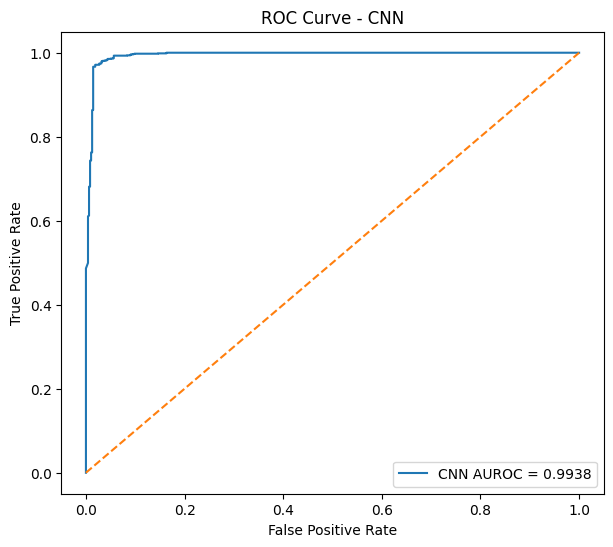

In [28]:
# ============================================================
# ROC CURVE
# ============================================================

fpr, tpr, thresholds = roc_curve(
    y_test_img,
    y_probability
)

roc_auc = auc(
    fpr,
    tpr
)

plt.figure(figsize=(7,6))

plt.plot(
    fpr,
    tpr,
    label=f"CNN AUROC = {roc_auc:.4f}"
)

plt.plot(
    [0,1],
    [0,1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("ROC Curve - CNN")

plt.legend()

plt.show()

Number of misclassified images: 49


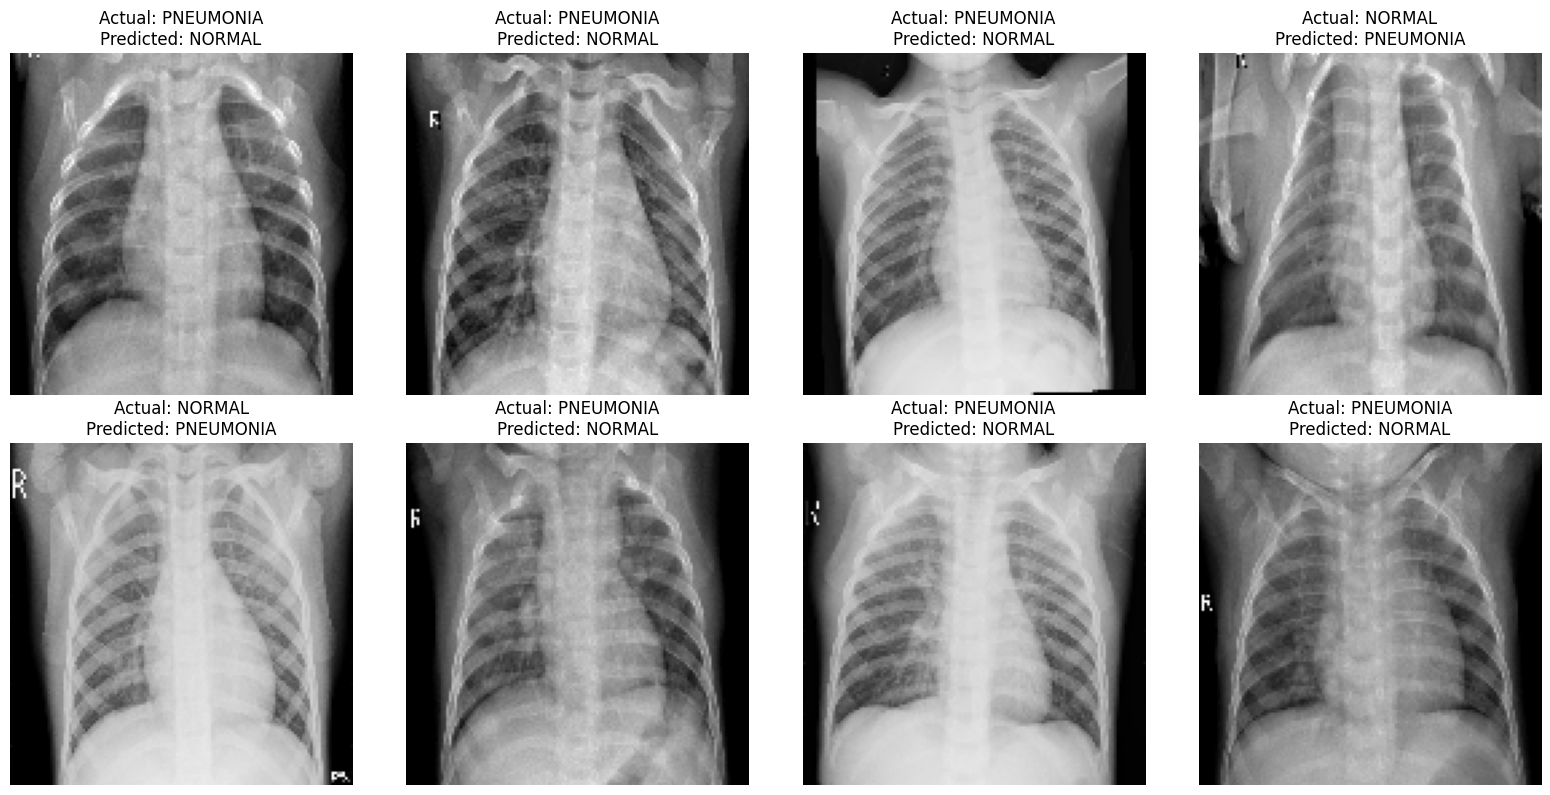

In [30]:
# ============================================================
# DISPLAY PREDICTIONS
# ============================================================

class_names = [
    "NORMAL",
    "PNEUMONIA"
]

wrong_indices = np.where(
    y_prediction != y_test_img
)[0]

print(
    "Number of misclassified images:",
    len(wrong_indices)
)

n_display = min(
    8,
    len(wrong_indices)
)

if n_display > 0:

    plt.figure(figsize=(16,8))

    selected_indices = wrong_indices[
        :n_display
    ]

    for i, idx in enumerate(
        selected_indices
    ):

        plt.subplot(2,4,i+1)

        plt.imshow(
            X_test_img[idx]
        )

        actual = class_names[
            y_test_img[idx]
        ]

        predicted = class_names[
            y_prediction[idx]
        ]

        plt.title(
            f"Actual: {actual}\n"
            f"Predicted: {predicted}"
        )

        plt.axis("off")

    plt.tight_layout()
    plt.show()

In [31]:
# ============================================================
# FINAL RESULTS TABLE
# ============================================================

results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "AUROC"
    ],

    "CNN": [
        accuracy,
        precision,
        recall,
        f1,
        auroc
    ]
})

results["CNN"] = results["CNN"].round(4)

display(results)

,Metric,CNN
0,Accuracy,0.9723
1,Precision,0.9928
2,Recall,0.9690
3,F1 Score,0.9808
4,AUROC,0.9938


In [32]:
# ============================================================
# SAVE MODEL
# ============================================================

final_model.save(
    "/content/chest_xray_cnn_model.keras"
)

print(
    "CNN model saved successfully."
)

CNN model saved successfully.
